# Two-link arm: open-loop tracking directly above the block

One task: start at `(0.50, 1.10)` m, follow one smooth reference, and finish directly
above the block at `(target_x, hover_y)`. No retreat/transit/alignment phases.
The target is reached through the reference trajectory itself; its endpoint is repeated
for `hold_steps`. This notebook is self-contained and needs NumPy, SciPy, Matplotlib,
and IPython, without MuJoCo.

Both notebooks use exact state observations and identical seeded physical kicks.
Closed loop replans from the disturbed robot state every step; open loop solves once.
The rolling and full-schedule horizons differ, so this compares controller strategies.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from scipy.optimize import minimize

L = 0.8
MISMATCH_WEIGHT = 40  # weight for mismatch penalty in the cost function
TERMINAL_WEIGHT = 120  # weight for terminal mismatch penalty
VELOCITY_REGULARIZATION = 0.05  # weight for velocity regularization
dt = 0.10
target_x = 1.5
hover_y = 0.24
tip_speed_limit = 0.35  # m/s per Cartesian component
joint_acceleration_limit = 0.2  # rad/s^2: max command change is 0.02 rad/s per step
joint_speed_limit = 1.5
kick_bias = np.array([0.0, 0.0])  # additive position disturbance [rad]
kick_std = np.array([0.001, 0.001])  # per executed interval, not velocity noise
kick_steps = None  # None: every interval; [40]: one kick after command 40 (zero-based)
mismatch_seed = 7
reference_samples = 100
hold_steps = 20  # repeat the same final target; no separate alignment problem
prediction_horizon = 8  # closed-loop only; open-loop covers the whole schedule
solver_maxiter = 160

assert kick_bias.shape == kick_std.shape == (2,)
assert np.isfinite(kick_bias).all() and np.isfinite(kick_std).all() and (kick_std >= 0).all()


## Same robot, obstacles and collision geometry
The state is two joint angles; joint 2 is relative to link 1. Controls are joint velocities. All circle clearances, table/box margins, and joint bounds are retained.


In [3]:
class TwoLinkRobot:
    def __init__(self, L=1.0, base=(0.0, 0.10)):
        self.L = float(L)
        self.base = np.asarray(base, dtype=float)

    def forward(self, q):
        q = np.asarray(q)
        a, b = q[..., 0], q[..., 0] + q[..., 1]
        elbow = self.base + self.L * np.stack([np.cos(a), np.sin(a)], axis=-1)
        tip = elbow + self.L * np.stack([np.cos(b), np.sin(b)], axis=-1)
        base = np.broadcast_to(self.base, elbow.shape)
        return np.stack([base, elbow, tip], axis=-2)

    def jacobian(self, q):
        """Tip velocity = J(q) @ joint velocity; batch dimensions supported."""
        q = np.asarray(q)
        a, b = q[..., 0], q[..., 0] + q[..., 1]
        row_x = self.L * np.stack([-np.sin(a)-np.sin(b), -np.sin(b)], axis=-1)
        row_y = self.L * np.stack([np.cos(a)+np.cos(b), np.cos(b)], axis=-1)
        return np.stack([row_x, row_y], axis=-2)

    def inverse(self, p):
        p = np.asarray(p) - self.base
        c = (np.sum(p*p, axis=-1) - 2*self.L**2) / (2*self.L**2)
        if np.any(np.abs(c) > 1 + 1e-10):
            raise ValueError("Requested initial/reference point is unreachable")
        q2_signed = -np.arccos(np.clip(c, -1.0, 1.0))
        q1 = np.arctan2(p[..., 1], p[..., 0]) - np.arctan2(
            self.L * np.sin(q2_signed),
            self.L * (1 + np.cos(q2_signed)),
        )
        q2 = q2_signed % (2 * np.pi)
        return np.stack([q1, q2], axis=-1)

robot = TwoLinkRobot(L)

sphere_radius = 0.06
d_ground, d_box = 0.02, 0.03
fractions = np.linspace(0.0, 1.0, 11)
box_half = np.array([0.055, 0.04])
box_center = np.array([target_x, box_half[1]])

def sphere_centers(q):
    joints = robot.forward(q)
    starts, ends = joints[..., :-1, :], joints[..., 1:, :]
    centers = starts[..., :, None, :] + fractions[:, None] * (
        ends - starts)[..., :, None, :]
    return centers.reshape(*joints.shape[:-2], -1, 2)

def box_sdf(p):
    delta = np.abs(np.asarray(p) - box_center) - box_half
    return np.linalg.norm(np.maximum(delta, 0), axis=-1) + np.minimum(
        np.max(delta, axis=-1), 0)

def collision_residuals(q):
    centers = sphere_centers(q)
    ground = centers[..., 1] - sphere_radius - d_ground
    target = box_sdf(centers) - sphere_radius - d_box
    return np.concatenate([ground, target], axis=-1)


## Shared reference and seeded physical kicks
Kicks are indexed by executed interval, independently of optimizer iterations.
`kick_schedule[k]` is added after command k; the initial state is exact and unperturbed.
Set `kick_std` to zero and `kick_bias` to a desired vector with `kick_steps=[40]`
for one deterministic kick. Both notebooks use the same defaults.


Goal [x,y] m: [1.5  0.24]
Physical kick RMS [rad]: [0.00092841 0.00088897]
119 execution intervals; 11.9 s; no alignment phase


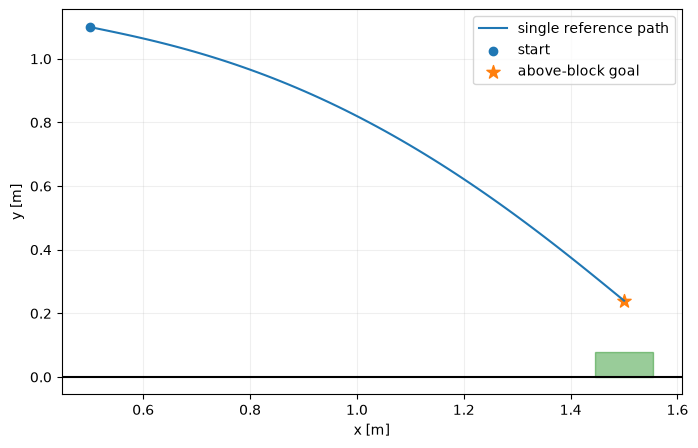

In [4]:
# One reference trajectory ends DIRECTLY above the block center.
def trajectory_function(s):
    start = np.array([0.50, 1.10])
    goal = np.array([target_x, hover_y])
    blend = 3*s*s - 2*s*s*s
    points = start + blend[:,None]*(goal-start)
    points[:,1] += .15*np.sin(np.pi*s)**2
    return points

reference = trajectory_function(np.linspace(0,1,reference_samples))
final_goal = np.array([target_x,hover_y])
full_reference = np.vstack([reference,np.tile(final_goal,(hold_steps,1))])
num_steps = len(full_reference)-1
times = np.arange(num_steps+1)*dt
q_true_initial = robot.inverse(reference[0])
assert np.allclose(reference[-1], final_goal)
assert collision_residuals(robot.inverse(full_reference)).min() >= 0, 'Reference collides'
kick_schedule = kick_bias + np.random.default_rng(mismatch_seed).normal(size=(num_steps,2))*kick_std
if kick_steps is not None:
    indices = np.asarray(kick_steps)
    assert indices.ndim == 1 and (indices.size == 0 or np.issubdtype(indices.dtype, np.integer))
    assert ((indices >= 0) & (indices < num_steps)).all()
    active = np.zeros(num_steps, dtype=bool)
    active[indices.astype(int)] = True
    kick_schedule[~active] = 0.0
q_mpc_initial = q_true_initial.copy()
print('Goal [x,y] m:',final_goal)
print('Physical kick RMS [rad]:',np.sqrt(np.mean(kick_schedule**2,axis=0)))
print(f'{num_steps} execution intervals; {num_steps*dt:.1f} s; no alignment phase')
fig,ax=plt.subplots(figsize=(8,5))
ax.plot(reference[:,0],reference[:,1],label='single reference path')
ax.scatter(*reference[0],label='start');ax.scatter(*final_goal,marker='*',s=100,label='above-block goal')
ax.add_patch(Rectangle(box_center-box_half,*(2*box_half),color='green',alpha=.4))
ax.axhline(0,color='black');ax.set(xlabel='x [m]',ylabel='y [m]')
ax.grid(alpha=.2);ax.legend();plt.show()


## Prediction and constrained solver
This helper defines the one tracking problem used below. IK supplies an initial guess, not executed commands. Worst-sample residuals preserve the original sampled inequality feasibility conditions.


In [5]:
def euler_step(q,u,kick=None):
    # The optimizer's rollout stays nominal; only the physical plant receives a kick.
    nominal = np.asarray(q)+dt*np.asarray(u)
    return nominal if kick is None else nominal+np.asarray(kick)

def rollout(q0,controls):
    controls=np.asarray(controls)
    return np.vstack([q0,np.asarray(q0)+dt*np.cumsum(controls,axis=0)])

alpha=np.linspace(0,1,6)

def constraint_families(q0,controls,previous_command,executed_states=None):
    qs=rollout(q0,controls) if executed_states is None else np.asarray(executed_states)
    samples=qs[:-1,None,:]+alpha[None,:,None]*dt*controls[:,None,:]
    if executed_states is not None:
        # Include the post-kick endpoint as well as the pre-kick commanded motion.
        samples=np.concatenate([samples,qs[1:,None,:]],axis=1)
    tips=robot.forward(samples)[...,-1,:]
    radii=np.linalg.norm(tips-robot.base,axis=-1)
    residual=collision_residuals(samples)
    spheres_per_family=2*len(fractions)
    v=np.einsum('naij,nj->nai',robot.jacobian(samples),controls)
    return {
        'table clearance [m]':residual[...,:spheres_per_family].min(axis=(1,2)),
        'box clearance [m]':residual[...,spheres_per_family:].min(axis=(1,2)),
        'joint lower bounds [rad]':samples.min(axis=1),
        'joint upper bounds [rad]':(np.array([np.pi,2*np.pi])-samples).min(axis=1),
        'workspace inner [m]':(radii-.08).min(axis=1),
        'workspace outer [m]':(2*L-.02-radii).min(axis=1),
        'Cartesian speed [m/s]':(tip_speed_limit-np.abs(v)).min(axis=1),
        'joint command speed [rad/s]':joint_speed_limit-np.abs(controls),
        'command change [rad/s per step]':joint_acceleration_limit*dt-np.abs(
            np.diff(np.vstack([previous_command,controls]),axis=0)),
    }

solve_records=[]
def solve_plan(measured_q,refs,previous_command,warm=None):
    n=len(refs)
    def objective(z):
        u=z.reshape(n,2)
        error=robot.forward(rollout(measured_q,u)[1:])[:,-1]-refs
        return MISMATCH_WEIGHT*np.sum(error**2)+TERMINAL_WEIGHT*np.sum(error[-1]**2)+VELOCITY_REGULARIZATION*np.sum(u**2)
    def gradient(z):
        u=z.reshape(n,2)
        qs=rollout(measured_q,u)[1:]
        error=robot.forward(qs)[:,-1]-refs
        gq=2*MISMATCH_WEIGHT*np.einsum('npi,np->ni',robot.jacobian(qs),error)
        gq[-1]+=2*TERMINAL_WEIGHT*robot.jacobian(qs[-1]).T@error[-1]
        return (dt*np.cumsum(gq[::-1],axis=0)[::-1]+2*VELOCITY_REGULARIZATION*u).ravel()
    def inequalities(z):
        families=constraint_families(measured_q,z.reshape(n,2),previous_command)
        return np.concatenate([a.ravel() for a in families.values()])
    if warm is None:
        seed_q=np.vstack([measured_q,robot.inverse(refs)])
        initial=np.diff(seed_q,axis=0)/dt
    else:
        initial=np.asarray(warm).reshape(n,2)
    # Numerical initial guess only: respect command/slew boxes sequentially.
    previous=np.asarray(previous_command).copy()
    for j in range(n):
        initial[j]=np.clip(initial[j],np.maximum(-joint_speed_limit,previous-joint_acceleration_limit*dt),
                           np.minimum(joint_speed_limit,previous+joint_acceleration_limit*dt))
        previous=initial[j]
    progress=[]
    def callback(z):
        progress.append(float(objective(z)))
        if n>prediction_horizon and len(progress)%10==0:
            print(f'iteration {len(progress)}: objective={progress[-1]:.6g}',flush=True)
    result=minimize(objective,initial.ravel(),jac=gradient,method='SLSQP',
                    bounds=[(-joint_speed_limit,joint_speed_limit)]*(2*n),
                    constraints=[{'type':'ineq','fun':inequalities}],callback=callback,
                    options={'maxiter':solver_maxiter,'ftol':1e-9,'disp':False})
    residual=float(inequalities(result.x).min())
    solve_records.append(dict(success=bool(result.success),message=str(result.message),
                              iterations=int(result.nit),objective=float(result.fun),minimum_residual=residual))
    if not result.success or not np.isfinite(result.x).all() or residual < -1e-7:
        print(solve_records[-1])
        raise RuntimeError('Trajectory MPC failed; no unchecked command is applied.')
    return result.x.reshape(n,2),rollout(measured_q,result.x.reshape(n,2))


## Optimization problem and execution
For the exactly observed actual joint state $q^{robot}_k$, solve
$$\begin{aligned}
\min_{U}\quad &40\sum_{j=1}^{N}\|f(\bar q_j)-r_j\|^2
+120\|f(\bar q_N)-r_N\|^2+0.05\sum_{j=0}^{N-1}\|u_j\|^2\\
\text{subject to}\quad &\bar q_0=q^{robot}_k,\quad \bar q_{j+1}=\bar q_j+\Delta t\,u_j,\\
&|u_j|\le u_{max},\quad |u_j-u_{j-1}|\le a_{max}\Delta t,\\
&c(\bar q_{j,\alpha})\ge0,\quad |J(\bar q_{j,\alpha})u_j|\le v_{max}.
\end{aligned}$$
Here $c$ includes joint-angle/workspace bounds and all table/box sphere clearances;
$\bar q_{j,\alpha}=\bar q_j+\alpha\Delta t\,u_j$ uses six samples per interval.
The previous applied command is retained for the first command-rate constraint.
There are **no horizontal-height equalities** and no separate alignment target.
SLSQP is local; solver success and sampled feasibility are checked before execution.
The physical robot receives a position kick after each command:
$$q^{robot}_{k+1}=q^{robot}_k+\Delta t\,u_k+w_k,\qquad y_k=q^{robot}_k.$$
The optimizer predicts zero future kicks; measurements are exact.
Kicks are not clipped or projected. Nominal feasibility does not ensure disturbed
feasibility. The instantaneous jump has no finite velocity; plotted $J(q)u$ is
only the commanded motion between kicks. Post-kick endpoints are checked separately.

**Open loop:** solve once from the exact initial state and execute the fixed controls with kicks. Later exact observations are logged only.


In [6]:
# One solve for the entire trajectory, followed by fixed-control execution.
optimized_controls,nominal_q=solve_plan(q_mpc_initial,full_reference[1:],np.zeros(2))
assert len(solve_records)==1, 'Run this cell once after restarting/setup for one solve.'
nominal_tip=robot.forward(nominal_q)[:,-1]
robot_q=[q_true_initial.copy()]
for k,command in enumerate(optimized_controls):
    robot_q.append(euler_step(robot_q[-1],command,kick_schedule[k]))
robot_q=np.asarray(robot_q)
robot_tip=robot.forward(robot_q)[:,-1]
actual_times=times.copy();actual_reference=full_reference.copy()
observed_q=robot_q.copy()
observed_tip=robot.forward(observed_q)[:,-1]
state_error=robot_q-nominal_q
applied_kicks=kick_schedule.copy()
np.testing.assert_allclose(state_error,np.vstack([np.zeros(2),np.cumsum(applied_kicks,axis=0)]),atol=1e-12)
np.testing.assert_allclose(np.diff(robot_q,axis=0)-dt*optimized_controls,applied_kicks,atol=1e-12)
print('Optimizer solves:',len(solve_records),solve_records[-1])


iteration 10: objective=0.191811
iteration 20: objective=0.190052
iteration 30: objective=0.190018
iteration 40: objective=0.190018
Optimizer solves: 1 {'success': True, 'message': 'Optimization terminated successfully', 'iterations': 40, 'objective': 0.1900178570747824, 'minimum_residual': 0.004286735154254623}


## Actual robot minus the reference
The right panel is actual tip position minus the **same desired reference**, in millimetres. This is the Cartesian tracking term used by the objective, evaluated on actual execution rather than a prediction. Zero means correct tracking. Final x/y goal errors and Euclidean distance are also printed.


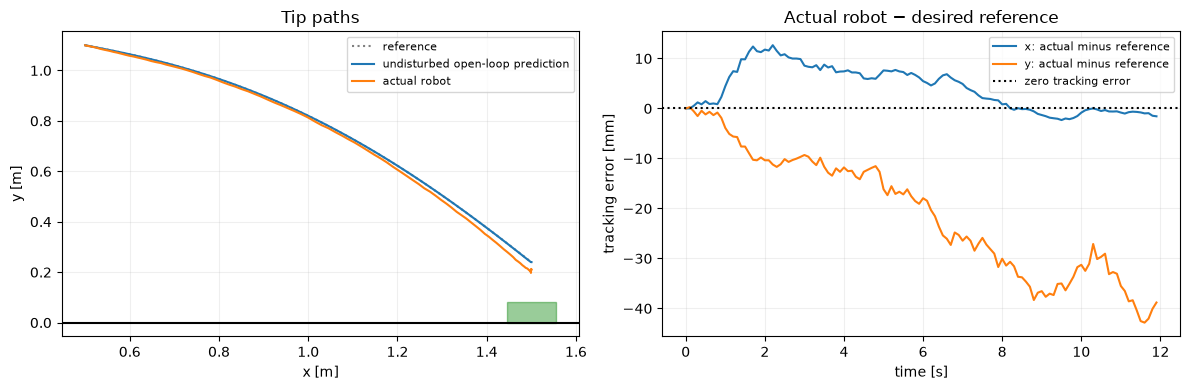

Last actual tip [x,y] m: [1.49843526 0.2011827 ]
Fixed final goal [x,y] m: [1.5  0.24]
Final goal error [x,y] mm: [ -1.56474043 -38.81729516]
Distance to final goal: 38.849 mm
Within 1 mm of the final goal: False
Cartesian tracking RMSE: 24.879 mm


In [7]:
tracking_error=robot_tip-actual_reference
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(reference[:,0],reference[:,1],':',color='gray',label='reference')
axes[0].plot(nominal_tip[:,0],nominal_tip[:,1],label='undisturbed open-loop prediction')
axes[0].plot(robot_tip[:,0],robot_tip[:,1],label='actual robot')
#axes[0].scatter(observed_tip[:,0],observed_tip[:,1],s=7,alpha=.3,label='exact observations')
axes[0].add_patch(Rectangle(box_center-box_half,*(2*box_half),color='green',alpha=.4))
axes[0].axhline(0,color='black');axes[0].set(xlabel='x [m]',ylabel='y [m]',title='Tip paths')
for j,coordinate in enumerate('xy'):
    axes[1].plot(actual_times,tracking_error[:,j]*1000,label=f'{coordinate}: actual minus reference')
axes[1].axhline(0,color='black',linestyle=':',label='zero tracking error')
axes[1].set(xlabel='time [s]',ylabel='tracking error [mm]',title='Actual robot − desired reference')
for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.tight_layout();plt.show()
final_goal_error=robot_tip[-1]-final_goal
print('Last actual tip [x,y] m:',robot_tip[-1])
print('Fixed final goal [x,y] m:',final_goal)
print('Final goal error [x,y] mm:',final_goal_error*1000)
print(f'Distance to final goal: {np.linalg.norm(final_goal_error)*1000:.3f} mm')
print('Within 1 mm of the final goal:',bool(np.linalg.norm(final_goal_error)<.001))
print(f'Cartesian tracking RMSE: {np.sqrt(np.mean(np.sum(tracking_error**2,axis=1)))*1000:.3f} mm')


## Endpoint x/y versus time
The dotted horizontal lines are the fixed expected final coordinates, independent of measurements and outcome. The dashed curves are the time-indexed reference.


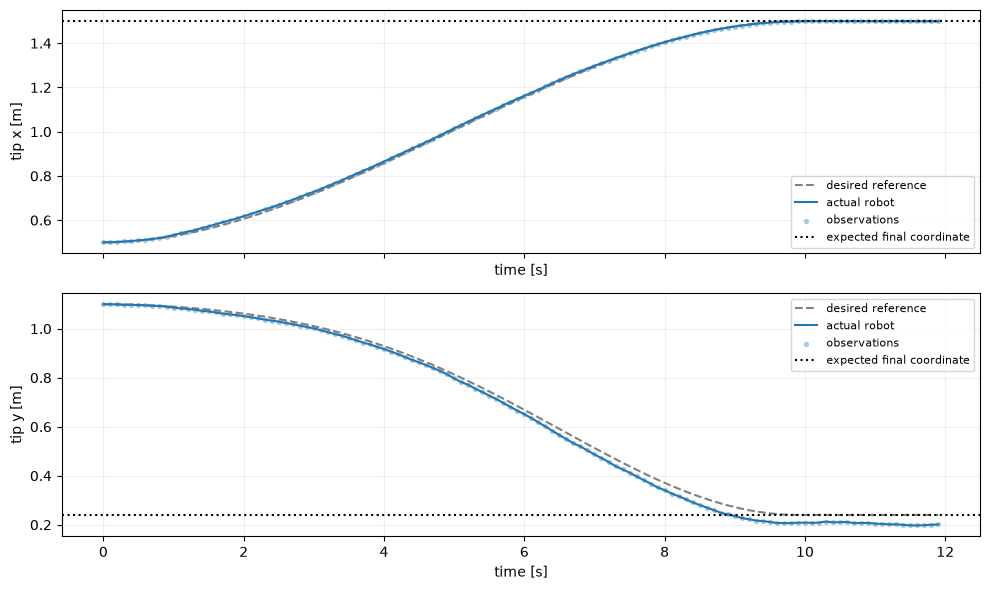

In [8]:
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
for j,coordinate in enumerate('xy'):
    axes[j].plot(times,full_reference[:,j],'--',color='gray',label='desired reference')
    axes[j].plot(actual_times,robot_tip[:,j],label='actual robot')
    axes[j].scatter(actual_times,observed_tip[:,j],s=8,alpha=.3,label='observations')
    axes[j].axhline(final_goal[j],color='black',linestyle=':',label='expected final coordinate')
    axes[j].set(ylabel=f'tip {coordinate} [m]',xlabel='time [s]')
    axes[j].grid(alpha=.2);axes[j].legend(fontsize=8)
fig.tight_layout();plt.show()


## Joint angles and commanded velocities
The robot integrates each commanded velocity, then receives a joint-position kick. No wrapping or projection is applied.


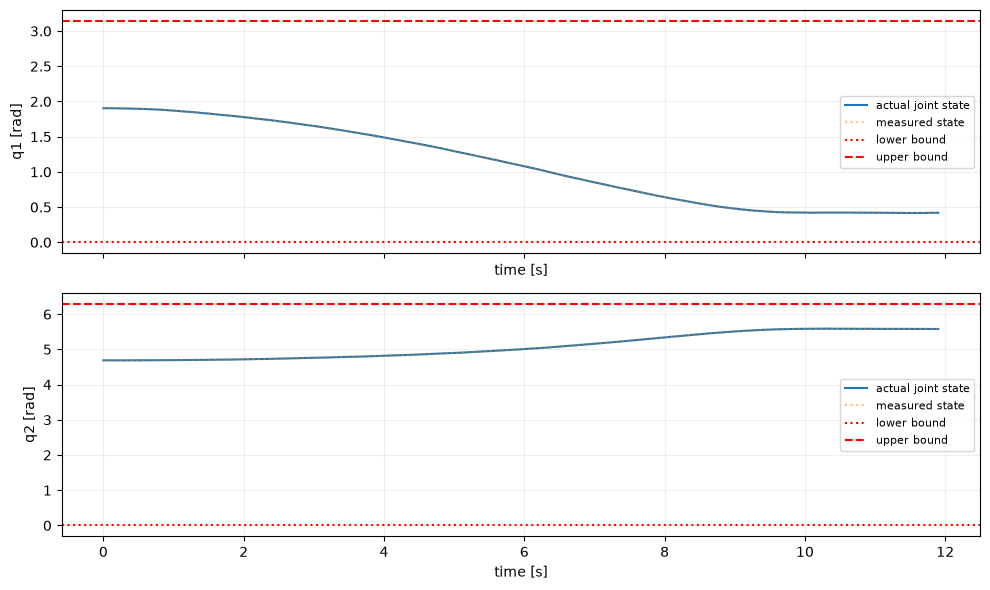

In [9]:
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
for j,upper in enumerate([np.pi,2*np.pi]):
    axes[j].plot(actual_times,robot_q[:,j],label='actual joint state')
    axes[j].plot(actual_times,observed_q[:,j],':',alpha=.5,label='measured state')
    axes[j].axhline(0,color='red',linestyle=':',label='lower bound')
    axes[j].axhline(upper,color='red',linestyle='--',label='upper bound')
    axes[j].set(ylabel=f'q{j+1} [rad]',xlabel='time [s]');axes[j].legend(fontsize=8);axes[j].grid(alpha=.2)
fig.tight_layout();plt.show()


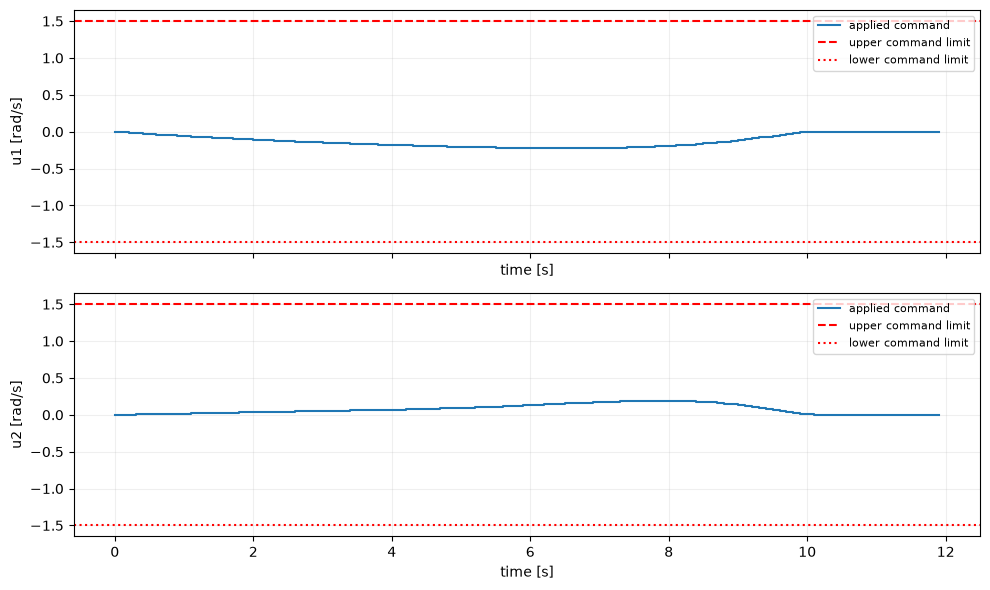

In [10]:
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
for j in range(2):
    if len(optimized_controls):
        axes[j].step(actual_times,np.r_[optimized_controls[:,j],optimized_controls[-1,j]],where='post',label='applied command')
    axes[j].axhline(joint_speed_limit,color='red',linestyle='--',label='upper command limit')
    axes[j].axhline(-joint_speed_limit,color='red',linestyle=':',label='lower command limit')
    axes[j].set(ylabel=f'u{j+1} [rad/s]',xlabel='time [s]');axes[j].legend(fontsize=8);axes[j].grid(alpha=.2)
fig.tight_layout();plt.show()


## Commanded Cartesian velocity and executed constraints
Velocity curves show $J(q)u$ during commanded motion, excluding instantaneous kicks.
Constraint diagnostics include pre-kick motion samples and post-kick states.
They report disturbed violations without correcting the physical state. The jump
itself has no modeled continuous path or finite velocity.


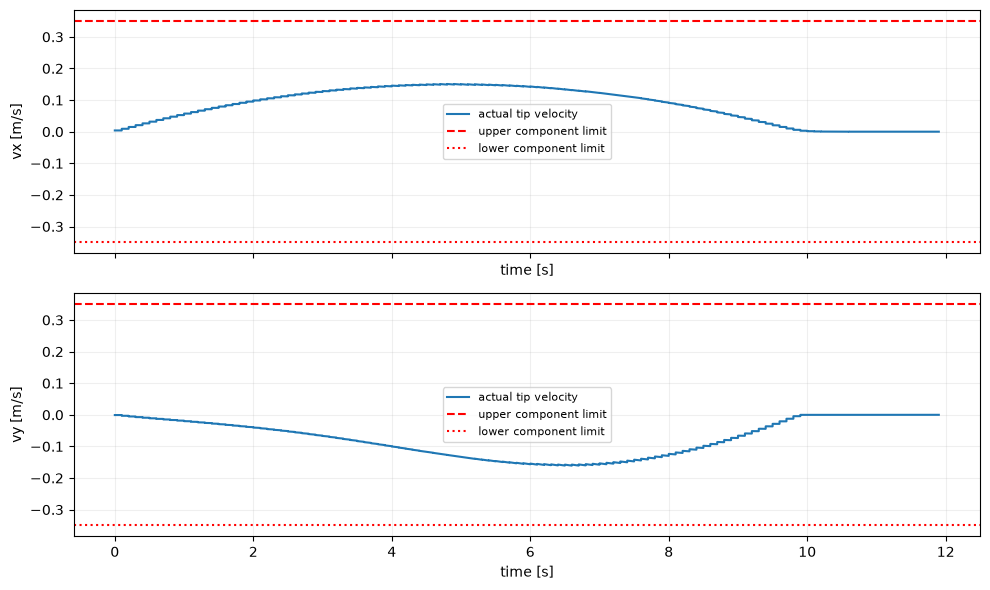

OK       table clearance [m]: +0.02
OK       box clearance [m]: +0.0271602
OK       joint lower bounds [rad]: +0.416048
OK       joint upper bounds [rad]: +0.695323
OK       workspace inner [m]: +1.03757
OK       workspace outer [m]: +0.0757247
OK       Cartesian speed [m/s]: +0.189063
OK       joint command speed [rad/s]: +1.27531
OK       command change [rad/s per step]: +0.00428674


In [11]:
if len(optimized_controls):
    motion=robot_q[:-1,None,:]+alpha[None,:,None]*dt*optimized_controls[:,None,:]
    tip_velocity=np.einsum('naij,nj->nai',robot.jacobian(motion),optimized_controls)
    sample_times=(np.arange(len(optimized_controls))[:,None]+alpha[None,:])*dt
    fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
    for j,coordinate in enumerate('xy'):
        axes[j].plot(sample_times.ravel(),tip_velocity[:,:,j].ravel(),label='actual tip velocity')
        axes[j].axhline(tip_speed_limit,color='red',linestyle='--',label='upper component limit')
        axes[j].axhline(-tip_speed_limit,color='red',linestyle=':',label='lower component limit')
        axes[j].set(ylabel=f'v{coordinate} [m/s]',xlabel='time [s]');axes[j].legend(fontsize=8);axes[j].grid(alpha=.2)
    fig.tight_layout();plt.show()
    executed_families=constraint_families(robot_q[0],optimized_controls,np.zeros(2),executed_states=robot_q)
    for family,residual in executed_families.items():
        worst=float(residual.min())
        print(f"{'VIOLATED' if worst < -1e-7 else 'OK':8s} {family}: {worst:+.6g}")


## Physical kicks
The measured state equals the actual state. The plotted residual isolates each physical kick, rather than accumulated tracking error.


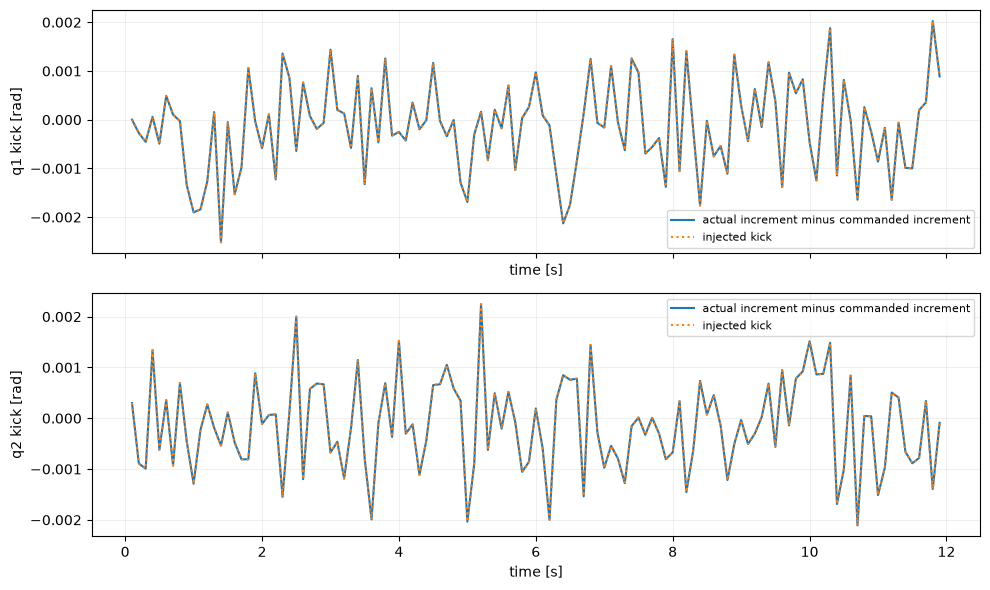

In [12]:
kick_residual=np.diff(robot_q,axis=0)-dt*optimized_controls
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
for j in range(2):
    axes[j].plot(actual_times[1:],kick_residual[:,j],label='actual increment minus commanded increment')
    axes[j].plot(actual_times[1:],applied_kicks[:,j],':',label='injected kick')
    axes[j].set(ylabel=f'q{j+1} kick [rad]',xlabel='time [s]')
    axes[j].legend(fontsize=8);axes[j].grid(alpha=.2)
fig.tight_layout();plt.show()


## Final above-block membership
The same triangular horizontal membership is gated by being above the block top. Degrees are not probabilities. The fixed desired endpoint is always `(target_x, hover_y)`.


reference goal: tip=[1.5  0.24]; above=1.0000; symbol=above
actual robot: tip=[1.49843526 0.2011827 ]; above=0.9716; symbol=above
last observation: tip=[1.49843526 0.2011827 ]; above=0.9716; symbol=above
MPC prediction: tip=[1.50000022 0.23999994]; above=1.0000; symbol=above


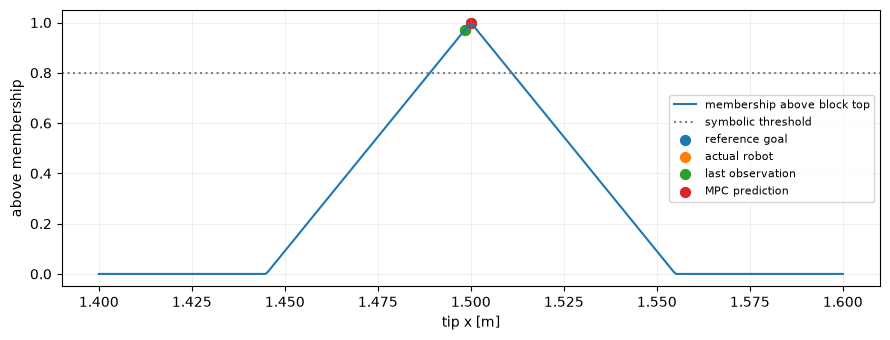

In [16]:
def above_membership(tip):
    return float(max(0,1-abs(tip[0]-target_x)/box_half[0])) if tip[1] > 2*box_half[1] else 0.

endpoints={'reference goal':final_goal,'actual robot':robot_tip[-1],'last observation':observed_tip[-1]}
endpoints['MPC prediction']=nominal_tip[-1]
xs=np.linspace(min(target_x-.1,*[p[0] for p in endpoints.values()]),max(target_x+.1,*[p[0] for p in endpoints.values()]),300)
fig,ax=plt.subplots(figsize=(9,3.5))
ax.plot(xs,[above_membership([x,hover_y]) for x in xs],label='membership above block top')
ax.axhline(.8,color='gray',linestyle=':',label='symbolic threshold')
for label,point in endpoints.items():
    mu=above_membership(point);ax.scatter(point[0],mu,label=label,s=50)
    print(f'{label}: tip={point}; above={mu:.4f}; symbol={"above" if mu>=.5 else "not above"}')
ax.set(xlabel='tip x [m]',ylabel='above membership',ylim=(-.05,1.05));ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.tight_layout();plt.show()


## Two-step analytic comparison
See [the derivation](two_link_kick_derivation.md) for the quadratic two-step problem from `open_closed_loop.pdf`, with physical kicks replacing observation error.


## Optional animation
This only visualizes the actual robot and reference; it does not solve another optimization problem.


In [17]:
fig,ax=plt.subplots(figsize=(8,6))
ax.set(xlim=(-.4,1.9),ylim=(-.12,1.8),xlabel='x [m]',ylabel='y [m]');ax.set_aspect('equal')
ax.axhline(0,color='black');ax.plot(reference[:,0],reference[:,1],':',color='gray',label='reference')
ax.add_patch(Rectangle(box_center-box_half,*(2*box_half),color='green',alpha=.4))
line,=ax.plot([],[],'o-',color='tab:orange',lw=2,label='actual robot')
trail,=ax.plot([],[],color='tab:orange',alpha=.5)
circles=[]
for _ in range(2*len(fractions)):
    circle=Circle((0,0),sphere_radius,fill=False,color='tab:orange',alpha=.35)
    ax.add_patch(circle);circles.append(circle)
status=ax.text(.02,.97,'',transform=ax.transAxes,va='top');ax.legend()
def animate(frame):
    joints=robot.forward(robot_q[frame]);line.set_data(joints[:,0],joints[:,1])
    trail.set_data(robot_tip[:frame+1,0],robot_tip[:frame+1,1])
    for circle,center in zip(circles,sphere_centers(robot_q[frame])):circle.center=center
    status.set_text(f't={actual_times[frame]:.1f} s | one trajectory to above block')
    return [line,trail,status]+circles
animation=FuncAnimation(fig,animate,frames=len(robot_q),interval=200,blit=False)
plt.close(fig);display(HTML(animation.to_jshtml()))


## Single physical kick: tracking error and feedback recovery
The final cell starts fresh at the exact same initial state in both notebooks, applies one deterministic joint-position kick at 4 s, and plots actual tip minus the time-indexed Cartesian reference. A fresh no-kick baseline separates ordinary tracking error from the disturbance response. No random kicks or measurement noise are used here. Change `single_kick_time` and `single_kick_delta` identically in both notebooks. Existing controller horizons are retained (rolling versus full schedule), so the comparison includes that strategy difference.


iteration 10: objective=0.191811
iteration 20: objective=0.190052
iteration 30: objective=0.190018
iteration 40: objective=0.190018
iteration 10: objective=0.191811
iteration 20: objective=0.190052
iteration 30: objective=0.190018
iteration 40: objective=0.190018
Open loop, No-kick baseline: completed; final tracking error = 0.000 mm
Open loop, Single-kick robot: completed; final tracking error = 8.000 mm


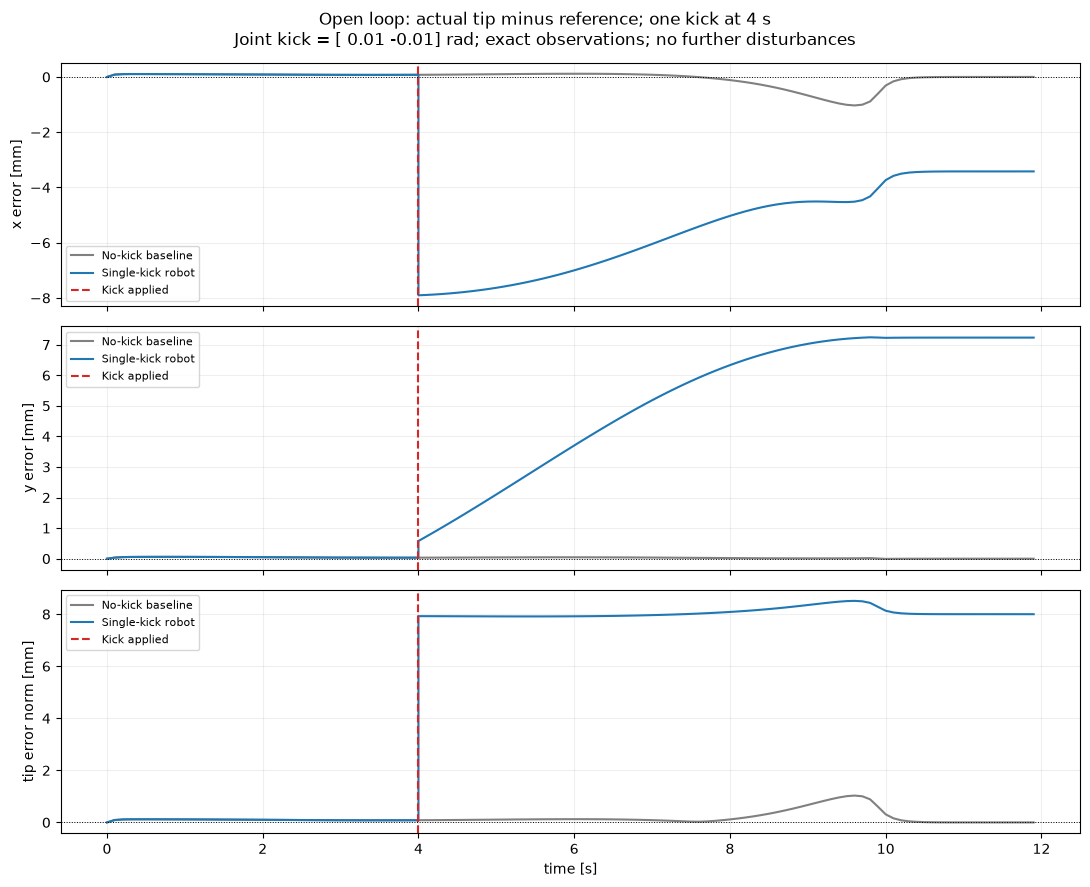

Initial joint state [rad]: [1.9042667  4.68894933]
Kick [rad]: [ 0.01 -0.01] at t = 4.0 s
Reference, weights, limits and kick must match between notebooks for comparison.


In [15]:
# Isolated single-kick experiment: restart at the same exact reference initial state.
# Identical experiment parameters in both notebooks; no observation/random noise.
single_kick_time = 4.0  # seconds; kick is applied at this control-node time
single_kick_delta = np.array([0.01, -0.01])  # additive joint-position kick [rad]
single_kick_node = int(round(single_kick_time / dt))
assert 1 <= single_kick_node <= num_steps
assert np.isclose(single_kick_node * dt, single_kick_time), 'Choose a control-node time'
assert single_kick_delta.shape == (2,) and np.isfinite(single_kick_delta).all()
experiment_initial_q = robot.inverse(full_reference[0]).copy()
experiment_schedule = np.zeros((num_steps, 2))
experiment_schedule[single_kick_node - 1] = single_kick_delta
experiment_closed_loop = False

def run_single_kick_experiment(schedule):
    states = [experiment_initial_q.copy()]
    commands = []
    previous = np.zeros(2)
    warm = None
    status = 'completed'
    plan = None
    record_start = len(solve_records)
    try:
        if not experiment_closed_loop:
            plan, _ = solve_plan(states[0], full_reference[1:], previous)
        for k in range(num_steps):
            if experiment_closed_loop:
                refs = full_reference[np.minimum(k + 1 + np.arange(prediction_horizon), num_steps)]
                plan, _ = solve_plan(states[-1], refs, previous, warm)
                command = plan[0].copy()
                warm = np.vstack([plan[1:], plan[-1]])
            else:
                command = plan[k].copy()
            commands.append(command)
            states.append(euler_step(states[-1], command, schedule[k]))
            previous = command
    except RuntimeError as exc:
        status = f'stopped after {len(commands)} intervals: {exc}'
    finally:
        # Keep this experiment separate from the main notebook's solve-count checks.
        records = solve_records[record_start:]
        del solve_records[record_start:]
    q = np.asarray(states)
    u = np.asarray(commands).reshape(-1, 2)
    np.testing.assert_allclose(np.diff(q, axis=0) - dt*u, schedule[:len(u)], atol=1e-12)
    return dict(q=q, controls=u, status=status, solves=records)

single_kick_baseline = run_single_kick_experiment(np.zeros_like(experiment_schedule))
single_kick_result = run_single_kick_experiment(experiment_schedule)
np.testing.assert_array_equal(single_kick_result['q'][0], single_kick_baseline['q'][0])
if len(single_kick_result['q']) > single_kick_node and len(single_kick_baseline['q']) > single_kick_node:
    np.testing.assert_allclose(single_kick_result['q'][:single_kick_node],
                               single_kick_baseline['q'][:single_kick_node], atol=1e-12)
    np.testing.assert_allclose(single_kick_result['q'][single_kick_node] -
        single_kick_baseline['q'][single_kick_node], single_kick_delta, atol=1e-12)
# Without feedback the kick leaves an exact, persistent joint-space offset.
if not experiment_closed_loop and single_kick_result['status'] == single_kick_baseline['status'] == 'completed':
    np.testing.assert_allclose(single_kick_result['q'] - single_kick_baseline['q'],
        np.vstack([np.zeros(2), np.cumsum(experiment_schedule, axis=0)]), atol=1e-12)

strategy = 'Closed loop' if experiment_closed_loop else 'Open loop'
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for result, label, color in [(single_kick_baseline, 'No-kick baseline', 'gray'),
                              (single_kick_result, 'Single-kick robot', 'tab:blue')]:
    q = result['q']
    t = np.arange(len(q))*dt
    tip = robot.forward(q)[:, -1]
    error = tip - full_reference[:len(q)]  # actual robot minus SAME time-indexed reference
    result['tracking_error'] = error
    result['times'] = t
    # Repeat the kick timestamp to show the instantaneous jump, not a gradual ramp.
    if label == 'Single-kick robot' and len(q) > single_kick_node:
        pre_kick_q = q[single_kick_node] - single_kick_delta
        pre_error = robot.forward(pre_kick_q)[-1] - full_reference[single_kick_node]
        t = np.insert(t, single_kick_node, single_kick_time)
        error = np.insert(error, single_kick_node, pre_error, axis=0)
    for j in range(2):
        axes[j].plot(t, error[:, j]*1000, label=label, color=color)
    axes[2].plot(t, np.linalg.norm(error, axis=1)*1000, label=label, color=color)
    print(f"{strategy}, {label}: {result['status']}; "
          f"final tracking error = {np.linalg.norm(result['tracking_error'][-1])*1000:.3f} mm")
for ax, ylabel in zip(axes, ['x error [mm]', 'y error [mm]', 'tip error norm [mm]']):
    ax.axvline(single_kick_time, color='tab:red', linestyle='--', label='Kick applied')
    ax.axhline(0, color='black', linewidth=.7, linestyle=':')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
axes[-1].set_xlabel('time [s]')
fig.suptitle(f'{strategy}: actual tip minus reference; one kick at {single_kick_time:g} s\n'
             f'Joint kick = {single_kick_delta} rad; exact observations; no further disturbances')
fig.tight_layout()
plt.show()
print('Initial joint state [rad]:', experiment_initial_q)
print('Kick [rad]:', single_kick_delta, 'at t =', single_kick_time, 's')
print('Reference, weights, limits and kick must match between notebooks for comparison.')


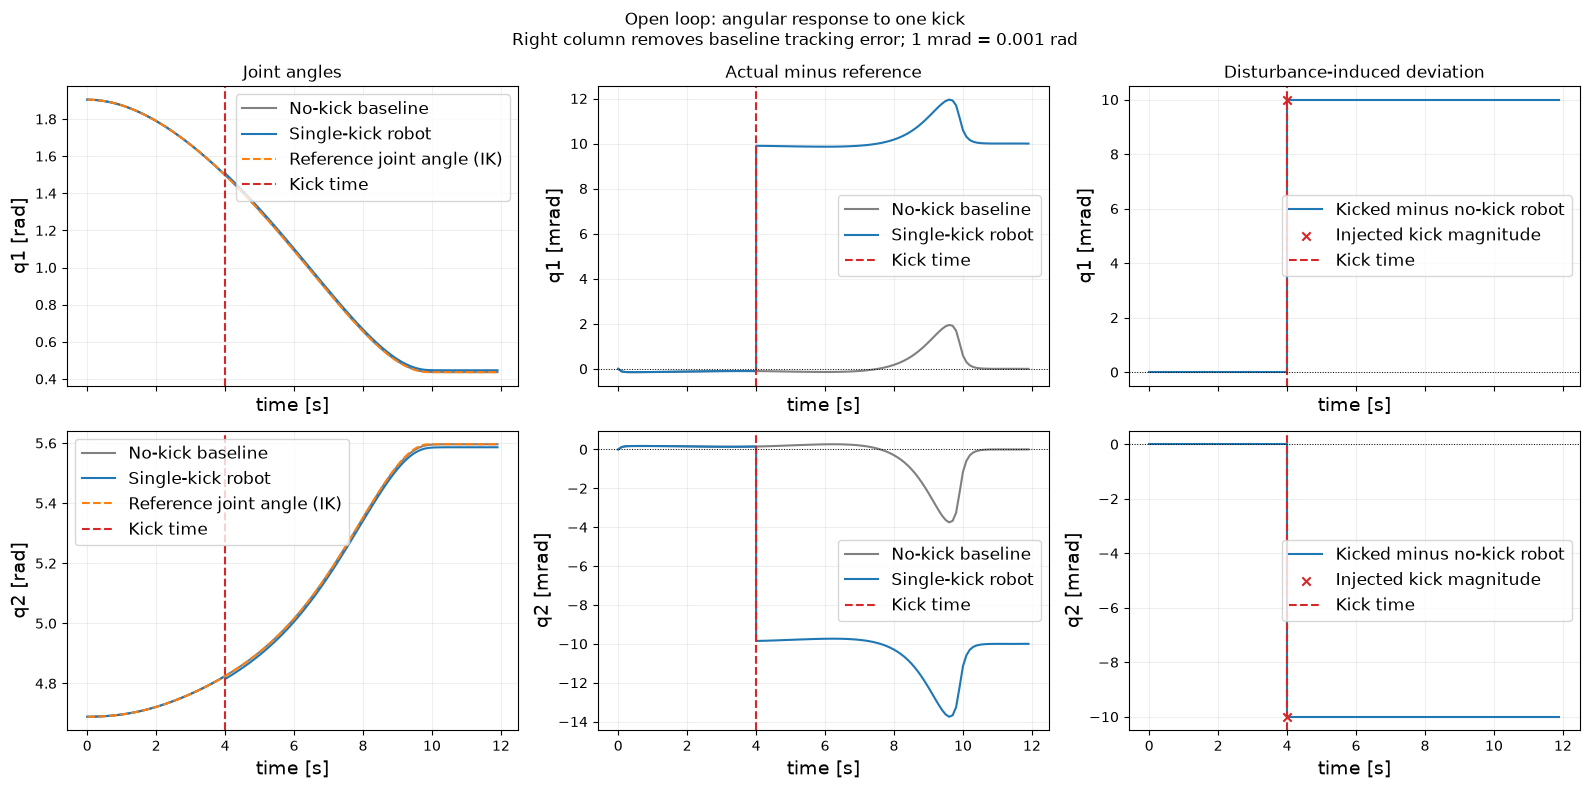

In [20]:
# Angular view of the single-kick experiment above; no new optimization is run.
angular_reference = robot.inverse(full_reference)  # same IK branch as initialization
fig_angles, axes_angles = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for result, label, color in [(single_kick_baseline, 'No-kick baseline', 'gray'),
                              (single_kick_result, 'Single-kick robot', 'tab:blue')]:
    q_angles = result['q'].copy()
    angle_times = np.arange(len(q_angles))*dt
    angle_error = q_angles - angular_reference[:len(q_angles)]
    # Draw an instantaneous jump at the kick timestamp rather than a sloped ramp.
    if label == 'Single-kick robot' and len(q_angles) > single_kick_node:
        pre_angles = q_angles[single_kick_node] - single_kick_delta
        pre_angle_error = pre_angles - angular_reference[single_kick_node]
        angle_times = np.insert(angle_times, single_kick_node, single_kick_time)
        q_angles = np.insert(q_angles, single_kick_node, pre_angles, axis=0)
        angle_error = np.insert(angle_error, single_kick_node, pre_angle_error, axis=0)
    for j in range(2):
        axes_angles[j, 0].plot(angle_times, q_angles[:, j], color=color, label=label)
        axes_angles[j, 1].plot(angle_times, angle_error[:, j]*1000, color=color, label=label)

# Subtract the matching no-kick run to isolate the disturbance response from
# ordinary tracking error. Use only times reached by both runs if either stopped.
common_nodes = min(len(single_kick_result['q']), len(single_kick_baseline['q']))
angular_disturbance = (single_kick_result['q'][:common_nodes]
                       - single_kick_baseline['q'][:common_nodes])
disturbance_times = np.arange(common_nodes)*dt
if common_nodes > single_kick_node:
    pre_disturbance = angular_disturbance[single_kick_node] - single_kick_delta
    disturbance_times = np.insert(disturbance_times, single_kick_node, single_kick_time)
    angular_disturbance = np.insert(angular_disturbance, single_kick_node, pre_disturbance, axis=0)
for j in range(2):
    axes_angles[j, 0].plot(np.arange(len(angular_reference))*dt, angular_reference[:, j],
                          '--', color='tab:orange', label='Reference joint angle (IK)')
    axes_angles[j, 2].plot(disturbance_times, angular_disturbance[:, j]*1000,
                          color='tab:blue', label='Kicked minus no-kick robot')
    axes_angles[j, 2].scatter([single_kick_time], [single_kick_delta[j]*1000],
                             color='tab:red', marker='x', zorder=5, label='Injected kick magnitude')
    for column, unit in enumerate(['rad', 'mrad', 'mrad']):
        ax = axes_angles[j, column]
        ax.axvline(single_kick_time, color='tab:red', linestyle='--', label='Kick time')
        if column > 0:
            ax.axhline(0, color='black', linewidth=.7, linestyle=':')
        #ax.set(xlabel='time [s]', ylabel=f'q{j+1} [{unit}]')
        ax.set_xlabel('time [s]', fontsize=14)
        ax.set_ylabel(f'q{j+1} [{unit}]', fontsize=14)
        ax.grid(alpha=.2)
        ax.legend(fontsize=12)
for ax, title in zip(axes_angles[0], ['Joint angles', 'Actual minus reference', 'Disturbance-induced deviation']):
    ax.set_title(title)
fig_angles.suptitle(f'{strategy}: angular response to one kick\n'
                   'Right column removes baseline tracking error; 1 mrad = 0.001 rad')
fig_angles.tight_layout()
plt.show()
